In [1]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
iris = load_iris()

df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

df['species'] = iris.target

df.head()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [3]:

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()


Dataset Shape: (150, 5)

Column Names:
Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)', 'species'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


In [4]:


df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


In [5]:


print(df.isnull().sum())


sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64


In [6]:


print("Duplicate rows:", df.duplicated().sum())


Duplicate rows: 1


In [7]:


df.describe()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [8]:


print(df['species'].value_counts())


species
0    50
1    50
2    50
Name: count, dtype: int64


In [9]:



df['species'] = df['species'].map({
    0: 'setosa',
    1: 'versicolor',
    2: 'virginica'
})



df.head()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


<Figure size 1200x800 with 0 Axes>

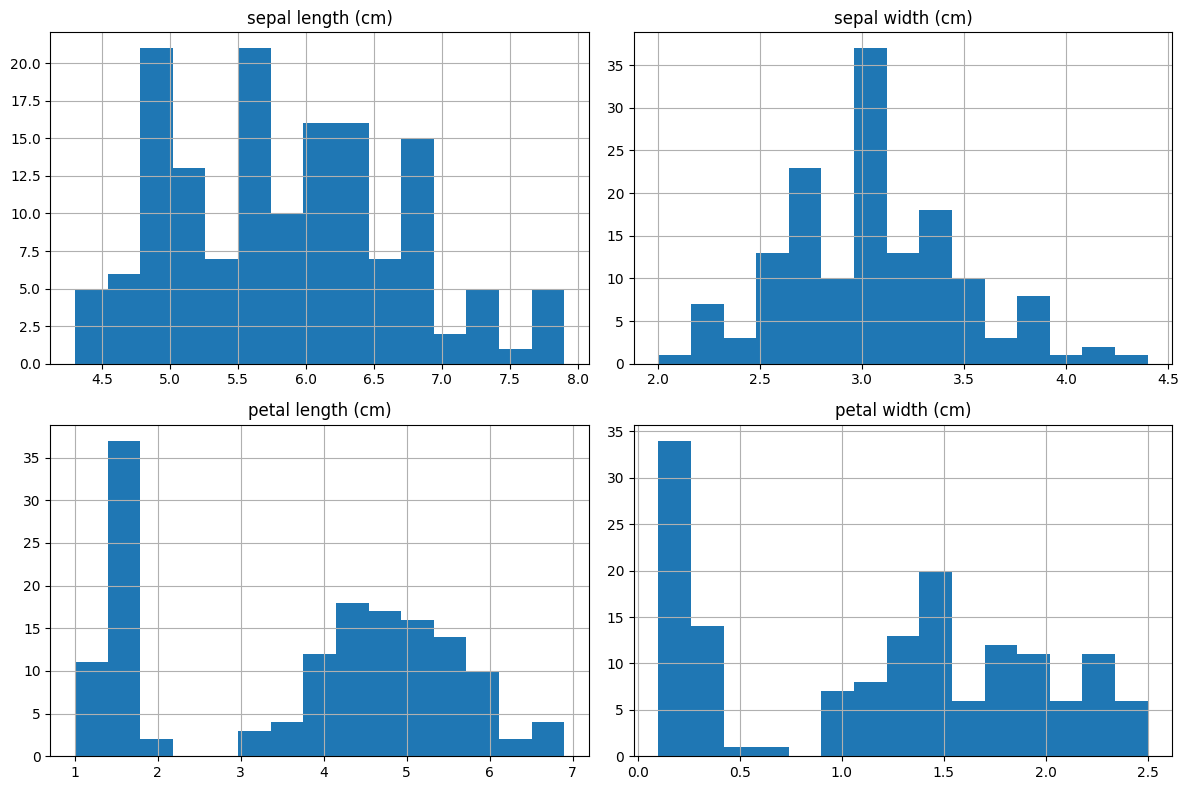

In [10]:

plt.figure(figsize=(12, 8))

df.hist(figsize=(12, 8), bins=15)

plt.tight_layout()
plt.show()


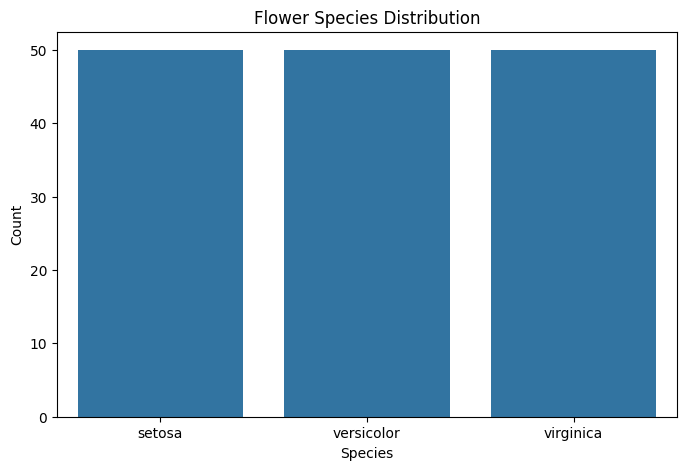

In [11]:

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='species')

plt.title('Flower Species Distribution')
plt.xlabel('Species')
plt.ylabel('Count')

plt.show()


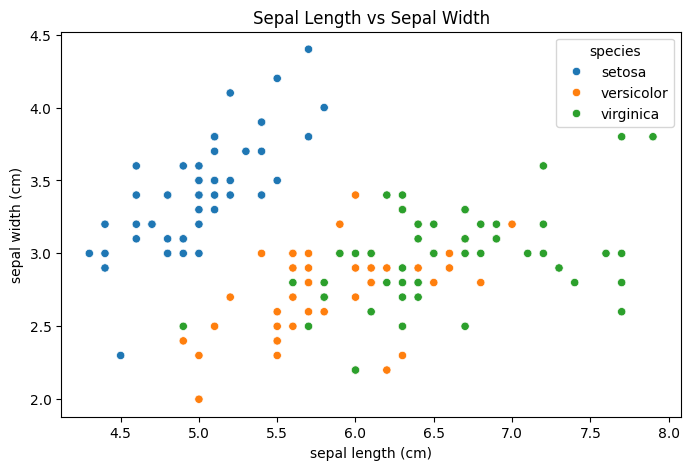

In [12]:

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='sepal length (cm)',
    y='sepal width (cm)',
    hue='species'
)

plt.title('Sepal Length vs Sepal Width')
plt.show()


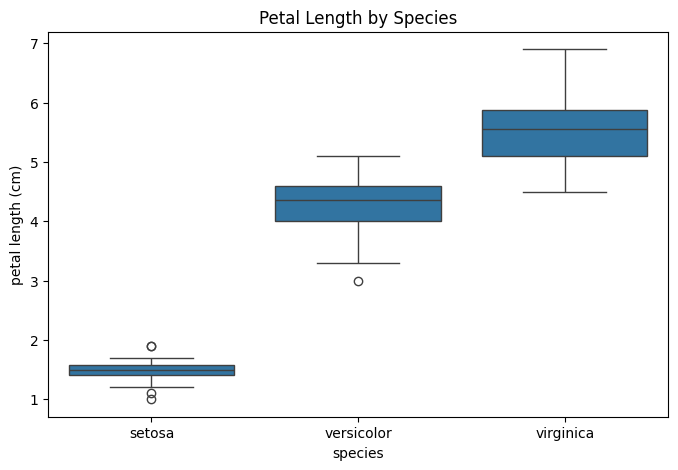

In [13]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='species',
    y='petal length (cm)'
)

plt.title('Petal Length by Species')
plt.show()


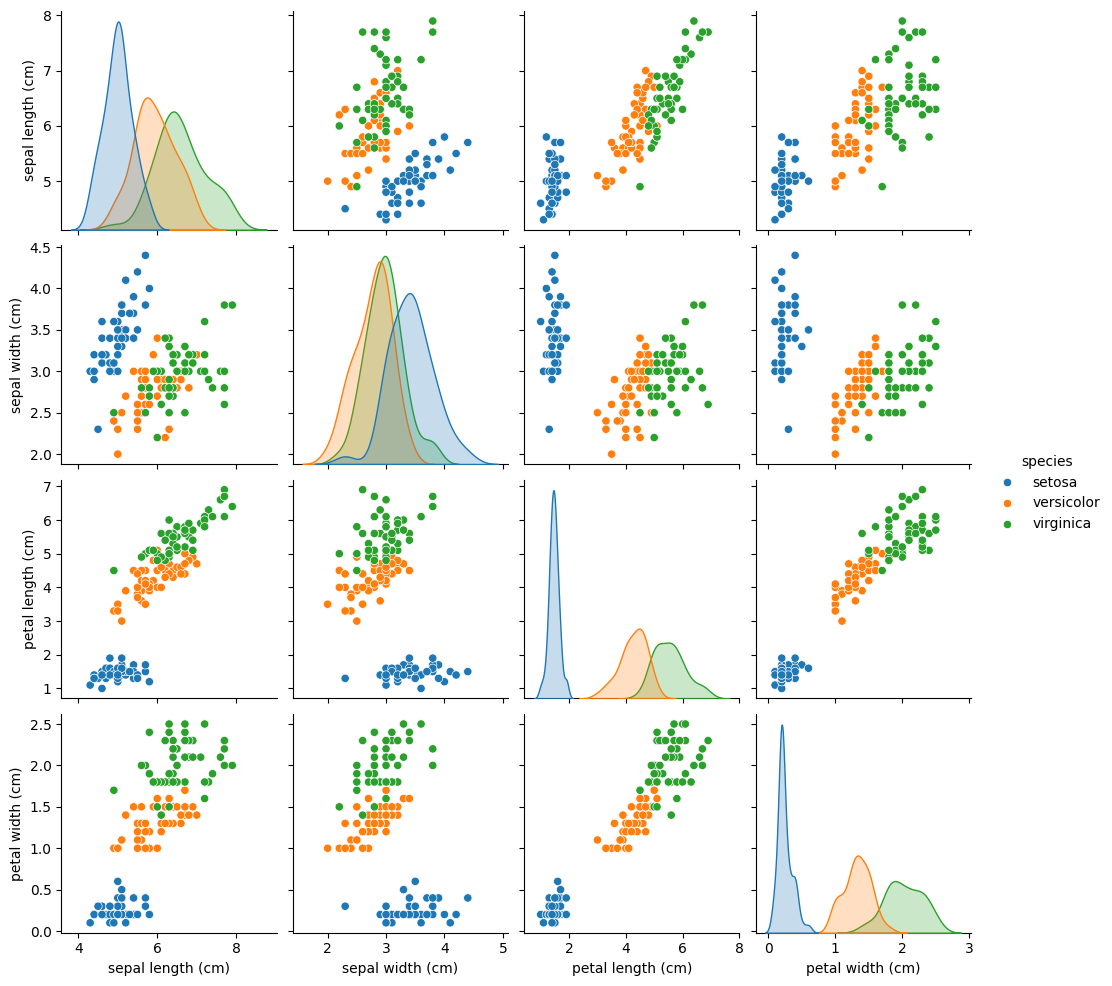

In [14]:

sns.pairplot(
    df,
    hue='species'
)

plt.show()


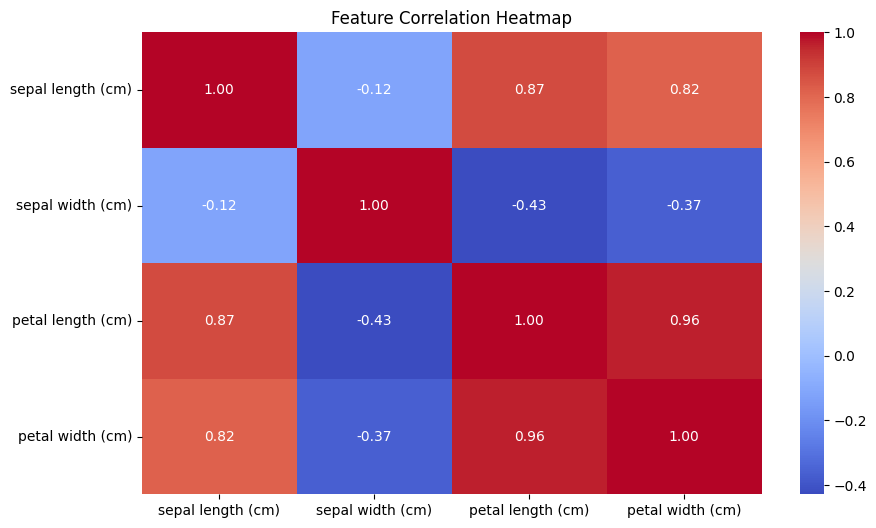

In [15]:

plt.figure(figsize=(10, 6))

correlation = df.drop(columns=['species']).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Feature Correlation Heatmap')
plt.show()


In [16]:

X = df.drop('species', axis=1)

y = df['species']


In [17]:

print(X.head())


   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2


In [18]:

print(y.head())


0    setosa
1    setosa
2    setosa
3    setosa
4    setosa
Name: species, dtype: object


In [19]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [20]:

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (120, 4)
X_test: (30, 4)
y_train: (120,)
y_test: (30,)


In [21]:

print(y_train.value_counts())
print(y_test.value_counts())


species
setosa        40
virginica     40
versicolor    40
Name: count, dtype: int64
species
setosa        10
virginica     10
versicolor    10
Name: count, dtype: int64


In [22]:

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier


In [23]:

log_model = LogisticRegression(max_iter=200)

log_model.fit(X_train, y_train)


LogisticRegression(max_iter=200)

In [24]:

log_predictions = log_model.predict(X_test)

print(log_predictions)


['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor' 'virginica'
 'virginica' 'virginica' 'versicolor' 'setosa' 'virginica' 'setosa']


In [25]:

tree_model = DecisionTreeClassifier(
    random_state=42
)

tree_model.fit(X_train, y_train)


DecisionTreeClassifier(random_state=42)

In [26]:

tree_predictions = tree_model.predict(X_test)

print(tree_predictions)


['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor' 'versicolor'
 'virginica' 'virginica' 'versicolor' 'setosa' 'virginica' 'setosa']


In [27]:

comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': log_predictions
})

print(comparison)


        Actual   Predicted
0       setosa      setosa
1    virginica   virginica
2   versicolor  versicolor
3   versicolor  versicolor
4       setosa      setosa
5   versicolor  versicolor
6       setosa      setosa
7       setosa      setosa
8    virginica   virginica
9   versicolor  versicolor
10   virginica   virginica
11   virginica   virginica
12   virginica   virginica
13  versicolor  versicolor
14      setosa      setosa
15      setosa      setosa
16      setosa      setosa
17  versicolor  versicolor
18  versicolor  versicolor
19   virginica   virginica
20      setosa      setosa
21   virginica   virginica
22  versicolor  versicolor
23   virginica   virginica
24   virginica   virginica
25  versicolor   virginica
26  versicolor  versicolor
27      setosa      setosa
28   virginica   virginica
29      setosa      setosa


In [28]:

comparison_tree = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': tree_predictions
})

print(comparison_tree)


        Actual   Predicted
0       setosa      setosa
1    virginica   virginica
2   versicolor  versicolor
3   versicolor  versicolor
4       setosa      setosa
5   versicolor  versicolor
6       setosa      setosa
7       setosa      setosa
8    virginica   virginica
9   versicolor  versicolor
10   virginica   virginica
11   virginica   virginica
12   virginica   virginica
13  versicolor  versicolor
14      setosa      setosa
15      setosa      setosa
16      setosa      setosa
17  versicolor  versicolor
18  versicolor  versicolor
19   virginica   virginica
20      setosa      setosa
21   virginica   virginica
22  versicolor  versicolor
23   virginica  versicolor
24   virginica   virginica
25  versicolor   virginica
26  versicolor  versicolor
27      setosa      setosa
28   virginica   virginica
29      setosa      setosa


In [29]:

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report


In [30]:

log_accuracy = accuracy_score(y_test, log_predictions)

print("Logistic Regression Accuracy:", log_accuracy)
print("Accuracy Percentage:", log_accuracy * 100, "%")


Logistic Regression Accuracy: 0.9666666666666667
Accuracy Percentage: 96.66666666666667 %


In [31]:

tree_accuracy = accuracy_score(y_test, tree_predictions)

print("Decision Tree Accuracy:", tree_accuracy)
print("Accuracy Percentage:", tree_accuracy * 100, "%")


Decision Tree Accuracy: 0.9333333333333333
Accuracy Percentage: 93.33333333333333 %


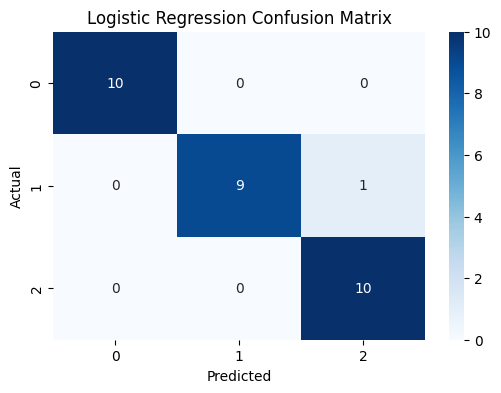

In [32]:

log_cm = confusion_matrix(y_test, log_predictions)

plt.figure(figsize=(6, 4))

sns.heatmap(
    log_cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()


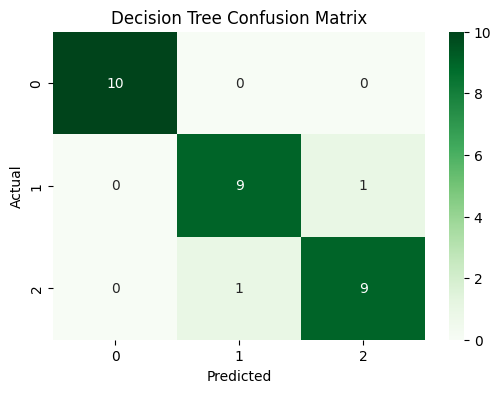

In [33]:

tree_cm = confusion_matrix(y_test, tree_predictions)

plt.figure(figsize=(6, 4))

sns.heatmap(
    tree_cm,
    annot=True,
    fmt='d',
    cmap='Greens'
)

plt.title('Decision Tree Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()


In [34]:

print(classification_report(y_test, log_predictions))


              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



In [35]:

print(classification_report(y_test, tree_predictions))


              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [36]:

model_comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree'],
    'Accuracy': [log_accuracy, tree_accuracy]
})

print(model_comparison)


                 Model  Accuracy
0  Logistic Regression  0.966667
1        Decision Tree  0.933333


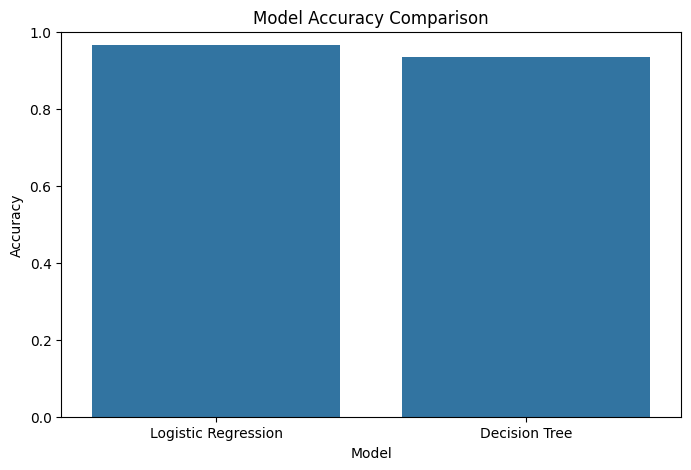

In [37]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=model_comparison,
    x='Model',
    y='Accuracy'
)

plt.title('Model Accuracy Comparison')
plt.ylabel('Accuracy')
plt.ylim(0, 1)

plt.show()


In [38]:

def predict_flower(sepal_length, sepal_width, petal_length, petal_width):

    new_flower = pd.DataFrame(
        [[sepal_length, sepal_width, petal_length, petal_width]],
        columns=X.columns
    )

    prediction = log_model.predict(new_flower)

    return prediction[0]


In [39]:

result = predict_flower(5.1, 3.5, 1.4, 0.2)

print("Predicted Flower Species:", result)


Predicted Flower Species: setosa


In [40]:

def flower_classification_cli():

    print("================================")
    print("     FLOWER CLASSIFICATION")
    print("================================")

    sepal_length = float(input("Enter Sepal Length: "))
    sepal_width = float(input("Enter Sepal Width: "))
    petal_length = float(input("Enter Petal Length: "))
    petal_width = float(input("Enter Petal Width: "))

    result = predict_flower(
        sepal_length,
        sepal_width,
        petal_length,
        petal_width
    )

    print("\nPredicted Flower Species:", result)

    print("================================")


In [50]:

flower_classification_cli()


     FLOWER CLASSIFICATION
Enter Sepal Length: 5.1
Enter Sepal Width: 3.5
Enter Petal Length: 1.4
Enter Petal Width: 0.2

Predicted Flower Species: setosa


In [42]:

import joblib
import os


In [44]:

os.makedirs('models', exist_ok=True)


In [45]:

joblib.dump(log_model, 'models/logistic_regression.pkl')


['models/logistic_regression.pkl']

In [46]:

joblib.dump(tree_model, 'models/decision_tree.pkl')


['models/decision_tree.pkl']

In [47]:

os.listdir('models')


['logistic_regression.pkl', 'decision_tree.pkl']

In [48]:

loaded_model = joblib.load('models/logistic_regression.pkl')


In [49]:

new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=X.columns
)

prediction = loaded_model.predict(new_flower)

print("Predicted Flower Species:", prediction[0])


Predicted Flower Species: setosa


In [51]:

import os

folders = [
    'Flower-Classification/dataset',
    'Flower-Classification/models',
    'Flower-Classification/notebooks',
    'Flower-Classification/src',
    'Flower-Classification/outputs'
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Project folders created successfully!")


Project folders created successfully!
